Dimensiones de la cuadrícula: 150 filas x 150 columnas.
Matriz transformada para K-Means (X): (22500, 3)
Primeros 3 píxeles (RGB):
[[117 154 165]
 [109 149 158]
 [ 45 116 122]]

--- INICIANDO K-MEANS (K=128) ---
Centroides iniciales (RGB):
[[ 56 117 109]
 [217 198 187]
 [  3  47  68]
 [207 179 173]
 [ 47  86 103]
 [199 172 158]
 [218 173 154]
 [157 149 145]
 [ 68 124 120]
 [147 113 124]
 [  1   2   6]
 [ 59  81  93]
 [148 168 175]
 [182 157 131]
 [  2  22  48]
 [ 98  86  81]
 [175 152 138]
 [  0   2   9]
 [190 172 160]
 [  7  97  90]
 [ 53  68  77]
 [202 195 186]
 [ 75  58  73]
 [  2  83 111]
 [ 33  51  58]
 [101 141 123]
 [  2  86 115]
 [ 69 121 133]
 [162 145 137]
 [ 18  86 108]
 [100 109 118]
 [  1  93 119]
 [ 44  39  44]
 [139 161 143]
 [139 155 152]
 [  2  89  76]
 [190 186 184]
 [ 20  20  33]
 [  1  61  93]
 [ 98  97  96]
 [ 80  85  91]
 [178 177 178]
 [204 175 166]
 [166 154 151]
 [160 161 162]
 [ 84 100 112]
 [ 86 123 129]
 [116 149 130]
 [ 75  91  95]
 [152 142 140]
 [  1  79 

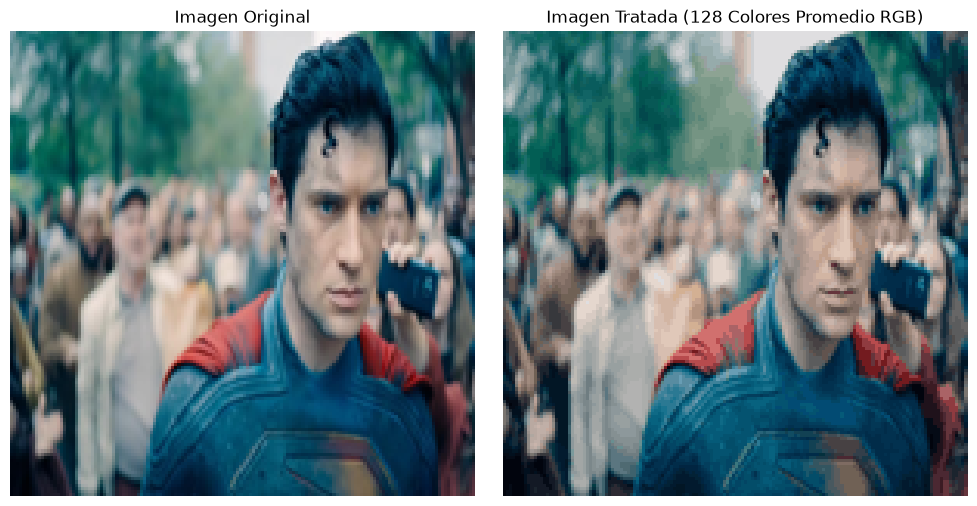

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image

# ==============================================================================
# PASO 1: CARGAR Y PREPARAR LA IMAGEN
# ==============================================================================
image_path = "/home/Jorge/diplomado/asset/superman2.jpg"
image = Image.open(image_path)

# Redimensionar para acelerar el procesamiento de píxeles
image = image.resize((150, 150))

# Convertir a arreglo de NumPy asegurando 3 canales RGB (elimina canal Alfa si es PNG)
img_array = np.array(image.convert("RGB"))

# Convertir de 3D (Alto x Ancho x 3) a 2D (Total de Píxeles x 3)
h, w, c = img_array.shape
X = img_array.reshape(-1, 3)

print(f"Dimensiones de la cuadrícula: {h} filas x {w} columnas.")
print(f"Matriz transformada para K-Means (X): {X.shape}")
print(f"Primeros 3 píxeles (RGB):\n{X[:3]}\n")


# ==============================================================================
# PASO 2: ALGORITMO K-MEANS PARA EXTRAER LOS COLORES PROMEDIO
# ==============================================================================
K = 128 # Número de colores dominantes deseados
epochs = 50 #10

# Inicializar centroides seleccionando K píxeles aleatorios de X
np.random.seed(42)
random_indices = np.random.choice(X.shape[0], K, replace=False)
centroids = X[random_indices].astype(float)

print(f"--- INICIANDO K-MEANS (K={K}) ---")
print(f"Centroides iniciales (RGB):\n{centroids.astype(int)}\n")

for epoch in range(epochs):
    # 1. Distancia euclidiana de cada píxel a cada centroide
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)

    # 2. Asignar cada píxel al centroide más cercano
    labels = np.argmin(distances, axis=1)

    # 3. Actualizar centroides al promedio RGB de su grupo
    new_centroids = np.zeros_like(centroids)
    for i in range(K):
        cluster_pixels = X[labels == i]
        if len(cluster_pixels) > 0:
            new_centroids[i] = cluster_pixels.mean(axis=0)
        else:
            new_centroids[i] = X[np.random.choice(X.shape[0])]

    # 4. Condición de convergencia
    if np.allclose(centroids, new_centroids):
        print(f"¡K-Means convergió en la época {epoch + 1}!")
        break

    centroids = new_centroids
    print(
        f"Época {epoch + 1}: Centroides actualizados (RGB):\n{centroids.astype(int)}\n"
    )

# ==============================================================================
# PASO 3: RECONSTRUCCIÓN Y VISUALIZACIÓN LADO A LADO EN UNA SOLA FIGURA
# ==============================================================================
# 1. Reemplazar el color de cada píxel por el promedio de su cluster (centroide)
X_promediado = centroids[labels].astype(np.uint8)

# 2. Regresar la matriz a las dimensiones 3D de la imagen (150 x 150 x 3)
img_promediada = X_promediado.reshape(h, w, c)

# 3. Mostrar la Imagen Original vs Imagen Cuantizada JUNTAS
plt.figure(figsize=(10, 5))

# Subplot 1: Izquierda (Imagen Original)
plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title("Imagen Original")
plt.axis("off")

# Subplot 2: Derecha (Imagen Tratada)
plt.subplot(1, 2, 2)
plt.imshow(img_promediada)
plt.title(f"Imagen Tratada ({K} Colores Promedio RGB)")
plt.axis("off")

# Ajustar espacio y mostrar una sola vez
plt.tight_layout()
plt.show()

In [12]:
# Definir el número de colores dominantes que queremos encontrar (ej. K=4)
K = 4 
epochs = 10

# 1.- Inicializar centroides seleccionando K píxeles aleatorios de la matriz X
np.random.seed(42)
random_indices = np.random.choice(X.shape[0], K, replace=False)
centroids = X[random_indices].astype(float)

print(f"--- INICIANDO K-MEANS PARA CUANTIZACIÓN DE COLOR (K={K}) ---")
print(f"Centroides iniciales (Colores RGB):\n{centroids.astype(int)}\n")

for epoch in range(epochs):
    # 2.- Cálculo de la matriz de distancias euclidianas
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    
    # 3.- Matriz de pertenencia / asignación 
    labels = np.argmin(distances, axis=1)
    
    # Resumen en la primera época
    if epoch == 0:
        print(f"Dimensiones de la matriz de distancias: {distances.shape}")
        print(f"Primeros 10 registros de la Matriz de Pertenencia:\n{labels[:10]}\n") 
        print("-" * 60)
        
    # 4.- Actualización de centroides (Mover al centro de masa del cluster)
    new_centroids = np.zeros_like(centroids)
    for i in range(K):
        cluster_pixels = X[labels == i]
        if len(cluster_pixels) > 0:
            new_centroids[i] = cluster_pixels.mean(axis=0)
        else:
            # Si un cluster queda vacío, se reasigna a un píxel aleatorio de X
            new_centroids[i] = X[np.random.choice(X.shape[0])]
    
    # Condición de convergencia
    if np.allclose(centroids, new_centroids):
        print(f"¡K-Means convergió matemáticamente en la época {epoch + 1}!")
        break
    
    centroids = new_centroids
    print(f"Época {epoch + 1}: Centroides actualizados:\n{centroids.astype(int)}\n")

print("¡Proceso de agrupamiento por K-Means completado con éxito!")

--- INICIANDO K-MEANS PARA CUANTIZACIÓN DE COLOR (K=4) ---
Centroides iniciales (Colores RGB):
[[  0   0   0]
 [234 190  93]
 [255 203  96]
 [ 93 255 234]]

Dimensiones de la matriz de distancias: (30000, 4)
Primeros 10 registros de la Matriz de Pertenencia:
[1 2 3 3 1 2 3 3 1 2]

------------------------------------------------------------
Época 1: Centroides actualizados:
[[ 44  30  84]
 [229 156  98]
 [250 231 166]
 [127 176 233]]

Época 2: Centroides actualizados:
[[ 42  71  86]
 [233 162  96]
 [248 235 179]
 [129 175 237]]

Época 3: Centroides actualizados:
[[ 45  91  83]
 [234 162  96]
 [248 235 180]
 [130 174 238]]

Época 4: Centroides actualizados:
[[ 48 112  76]
 [234 162  97]
 [248 235 180]
 [130 173 239]]

Época 5: Centroides actualizados:
[[ 51 127  72]
 [235 162  97]
 [247 235 180]
 [130 172 240]]

Época 6: Centroides actualizados:
[[ 58 145  55]
 [235 162  97]
 [247 235 180]
 [129 170 240]]

Época 7: Centroides actualizados:
[[ 59 148  56]
 [235 161  97]
 [247 235 180]
 [


--- PROCESANDO IMAGEN 4K ---


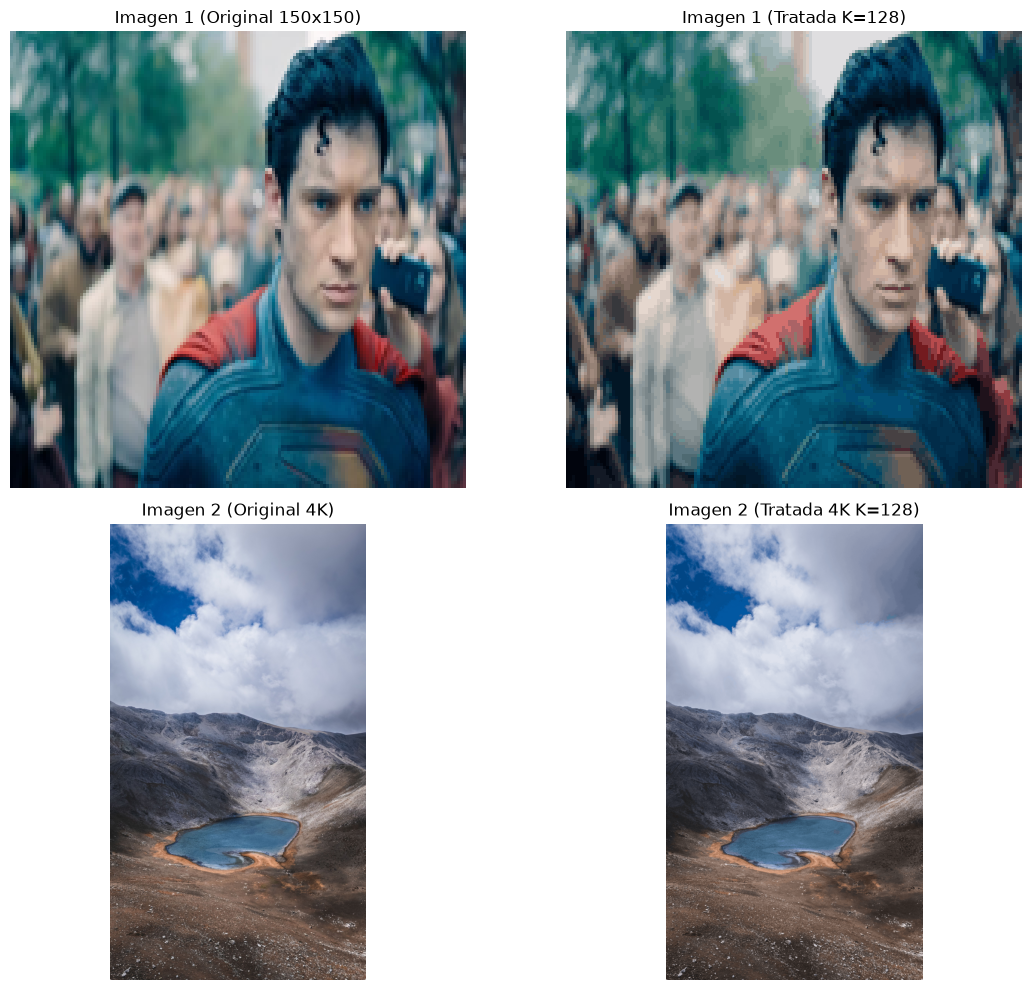

In [34]:
# ==============================================================================
# PASO ADICIONAL: PROCESAMIENTO OPTIMIZADO PARA IMAGEN 4K
# ==============================================================================
# ⚠️ Ruta de tu imagen 4K
image_4k_path = "/home/Jorge/diplomado/asset/toluca.jpg"

print(f"\n--- PROCESANDO IMAGEN 4K ---")
img_4k_raw = Image.open(image_4k_path).convert("RGB")
img_4k_array = np.array(img_4k_raw)
h_4k, w_4k, c_4k = img_4k_array.shape
X_4k_full = img_4k_array.reshape(-1, 3)

# 1. Submuestreo de 50,000 píxeles para calcular las épocas de K-Means rápido
np.random.seed(42)
sample_size = 50000
indices_muestra = np.random.choice(
    X_4k_full.shape[0], min(sample_size, X_4k_full.shape[0]), replace=False
)
X_4k_train = X_4k_full[indices_muestra]

# 2. Bucle K-Means en la muestra 4K
random_indices_4k = np.random.choice(X_4k_train.shape[0], K, replace=False)
centroids_4k = X_4k_train[random_indices_4k].astype(float)

for epoch in range(epochs):
    distances_4k = np.linalg.norm(
        X_4k_train[:, np.newaxis] - centroids_4k, axis=2
    )
    labels_4k_train = np.argmin(distances_4k, axis=1)

    new_centroids_4k = np.zeros_like(centroids_4k)
    for i in range(K):
        cluster_pixels = X_4k_train[labels_4k_train == i]
        if len(cluster_pixels) > 0:
            new_centroids_4k[i] = cluster_pixels.mean(axis=0)
        else:
            new_centroids_4k[i] = X_4k_train[
                np.random.choice(X_4k_train.shape[0])
            ]

    if np.allclose(centroids_4k, new_centroids_4k):
        print(f"¡K-Means 4K convergió en la época {epoch + 1}!")
        break
    centroids_4k = new_centroids_4k

# 3. Asignación por bloques (batch_size) para no saturar la RAM
labels_4k_full = np.zeros(X_4k_full.shape[0], dtype=np.int32)
batch_size = 500000

for start in range(0, X_4k_full.shape[0], batch_size):
    end = min(start + batch_size, X_4k_full.shape[0])
    batch_distances = np.linalg.norm(
        X_4k_full[start:end, np.newaxis] - centroids_4k, axis=2
    )
    labels_4k_full[start:end] = np.argmin(batch_distances, axis=1)

X_4k_promediado = centroids_4k[labels_4k_full].astype(np.uint8)
img_4k_promediada = X_4k_promediado.reshape(h_4k, w_4k, c_4k)


# ==============================================================================
# MOSTRAR AMBAS IMÁGENES Y SUS VERSIONES TRATADAS EN UN GRID (2x2)
# ==============================================================================
plt.figure(figsize=(12, 10))

# Fila 1: Imagen Base (150x150)
plt.subplot(2, 2, 1)
plt.imshow(img_array)
plt.title("Imagen 1 (Original 150x150)")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(img_promediada)
plt.title(f"Imagen 1 (Tratada K={K})")
plt.axis("off")

# Fila 2: Imagen 4K
plt.subplot(2, 2, 3)
plt.imshow(img_4k_array)
plt.title("Imagen 2 (Original 4K)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(img_4k_promediada)
plt.title(f"Imagen 2 (Tratada 4K K={K})")
plt.axis("off")

plt.tight_layout()
plt.show()


--- PROCESANDO IMAGEN 4K (DIFERENCIANDO AGUA Y CIELO) ---


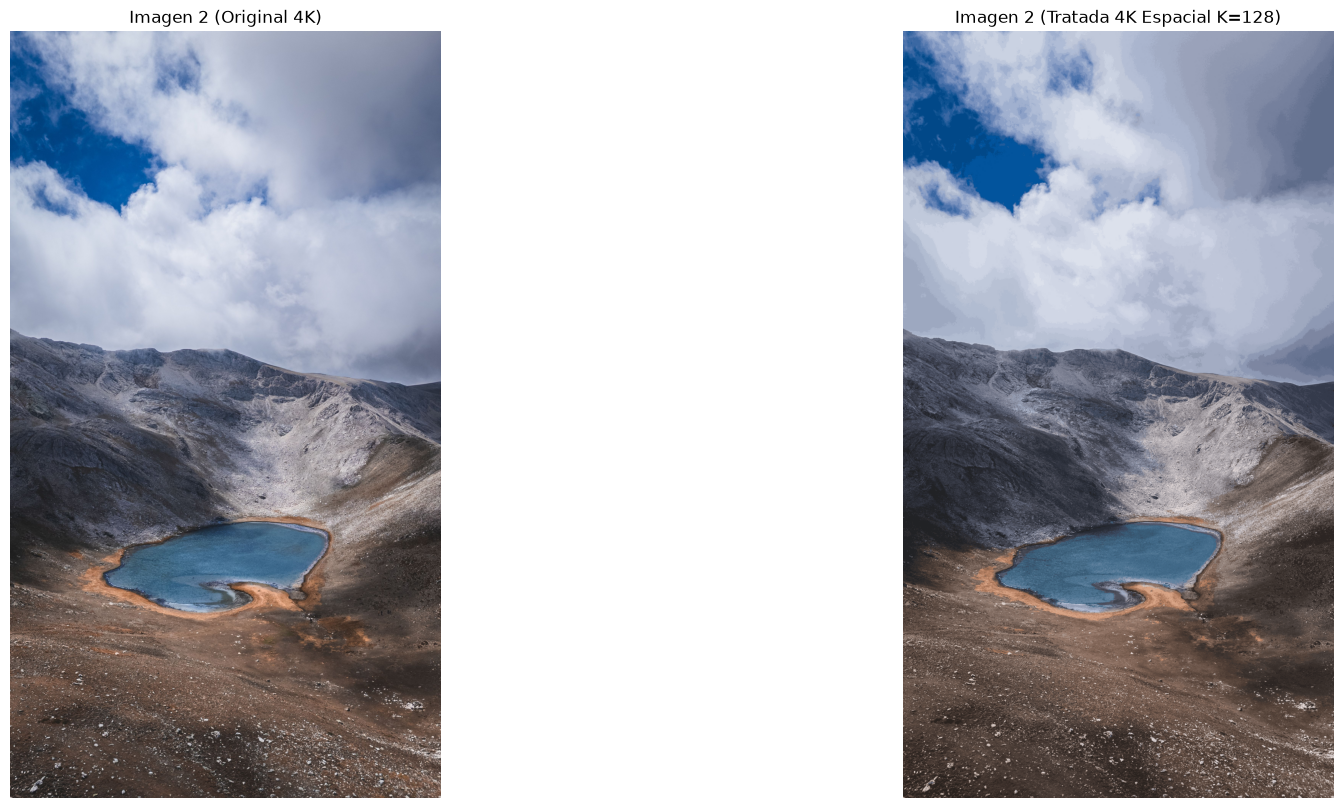

In [37]:
# ==============================================================================
# PASO 2 (CORREGIDO): PROCESAMIENTO OPTIMIZADO PARA IMAGEN 4K (COLOR + POSICIÓN)
# ==============================================================================
image_4k_path = "/home/Jorge/diplomado/asset/toluca.jpg"

print("\n--- PROCESANDO IMAGEN 4K (DIFERENCIANDO AGUA Y CIELO) ---")
img_4k_raw = Image.open(image_4k_path).convert("RGB")
img_4k_array = np.array(img_4k_raw)
h_4k, w_4k, c_4k = img_4k_array.shape
X_4k_full = img_4k_array.reshape(-1, 3)

# 1. Crear coordenadas X, Y normalizadas al rango 0-255 (igual que el RGB)
grid_y, grid_x = np.mgrid[0:h_4k, 0:w_4k]
norm_y = (grid_y / h_4k) * 255.0
norm_x = (grid_x / w_4k) * 255.0

# Factor de peso suave: 0.2 para que el color siga siendo el protagonista
peso_posicion = 0.2
features_5d = np.dstack(
    (img_4k_array, norm_y * peso_posicion, norm_x * peso_posicion)
)
X_5d_full = features_5d.reshape(-1, 5)

# 2. Submuestreo de 50,000 píxeles para calcular K-Means rápido
np.random.seed(42)
sample_size = 50000
indices_muestra = np.random.choice(
    X_5d_full.shape[0], min(sample_size, X_5d_full.shape[0]), replace=False
)
X_5d_train = X_5d_full[indices_muestra]

# 3. Entrenar K-Means con más épocas (30 épocas)
random_indices_4k = np.random.choice(X_5d_train.shape[0], K, replace=False)
centroids_5d = X_5d_train[random_indices_4k].astype(float)

epochs = 30  # Subimos a 30 para permitir mejor ajuste
for epoch in range(epochs):
    distances_4k = np.linalg.norm(
        X_5d_train[:, np.newaxis] - centroids_5d, axis=2
    )
    labels_4k_train = np.argmin(distances_4k, axis=1)

    new_centroids_5d = np.zeros_like(centroids_5d)
    for i in range(K):
        cluster_pixels = X_5d_train[labels_4k_train == i]
        if len(cluster_pixels) > 0:
            new_centroids_5d[i] = cluster_pixels.mean(axis=0)
        else:
            new_centroids_5d[i] = X_5d_train[
                np.random.choice(X_5d_train.shape[0])
            ]

    if np.allclose(centroids_5d, new_centroids_5d, atol=1e-2):
        print(f"¡K-Means 4K convergió en la época {epoch + 1}!")
        break
    centroids_5d = new_centroids_5d

# 4. Asignación por bloques seguros para no saturar la RAM
labels_4k_full = np.zeros(X_5d_full.shape[0], dtype=np.int32)
batch_size = 20000  # Bloques pequeños para estabilidad

for start in range(0, X_5d_full.shape[0], batch_size):
    end = min(start + batch_size, X_5d_full.shape[0])
    batch_distances = np.linalg.norm(
        X_5d_full[start:end, np.newaxis] - centroids_5d, axis=2
    )
    labels_4k_full[start:end] = np.argmin(batch_distances, axis=1)

# 5. Extraer SOLO las 3 primeras columnas (RGB) para reconstruir la imagen visible
centroids_rgb = np.clip(centroids_5d[:, :3], 0, 255).astype(np.uint8)
X_4k_promediado = centroids_rgb[labels_4k_full]
img_4k_promediada = X_4k_promediado.reshape(h_4k, w_4k, c_4k)


# ==============================================================================
# PASO 3: MOSTRAR LAS IMÁGENES
# ==============================================================================
plt.figure(figsize=(18, 16))  # Vista mucho más grande

# Fila 2: Imagen 4K
plt.subplot(2, 2, 3)
plt.imshow(img_4k_array)
plt.title("Imagen 2 (Original 4K)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(img_4k_promediada)
plt.title(f"Imagen 2 (Tratada 4K Espacial K={K})")
plt.axis("off")

plt.tight_layout()
plt.show()